<a href="https://colab.research.google.com/github/delaneydow/ncl_diffusion/blob/main/04_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Generate and evaluate: diffusion vs GAN

Samples both generators from the **same label plans**, then evaluates them on the same held-out real images:

1. **Generation:** one label matrix per purpose, saved to disk and reused for both models (plus a zero-label "healthy" set for the healthy-brain question).
2. **Distribution metrics:** FID and KID against the real **test** split, with a real-vs-real floor so the numbers are interpretable, plus a diversity check.
3. **Memorization:** nearest-training-image distances, always compared with the same distance for held-out *real* images.
4. **Classifier sweep:** real train + synthetic (ratios 0, 0.5, 1, 2), several seeds, paired differences vs the real-only baseline.
5. **Ablations** (guidance scale) and a **blinded reader-study export** for radiology.

The notebook is parameterised by `VARIANT` / run names, so for the skull-stripped comparison you rerun it with the skull-stripped runs; results go to `eval/<variant>/`.

**Read before trusting the classifier sweep:** the generators were trained on 100% of the real train rows, so this notebook only runs the sweep at 100% real data. A low-real-data sweep (10%, 25%) would leak information from the held-back rows through the generators, so it needs generators retrained on each subset.

In [ ]:
# ====== BOOTSTRAP (identical in every notebook) ======
# Mounts Drive, links the project folder, installs anything missing, puts the package on sys.path.
import os, sys, importlib.util, importlib.metadata, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules

PROJECT = "/content/drive/MyDrive/ncl_diffusion" if IN_COLAB else os.path.abspath("ct_diffusion_project")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(PROJECT, exist_ok=True)
LINK = "/content/ncl_diffusion_project" if IN_COLAB else PROJECT   # short path used everywhere below
if LINK != PROJECT and not os.path.exists(LINK):
    os.symlink(PROJECT, LINK)

# pip name -> import name.
# NOTE: no `monai-generative` any more. MONAI >= 1.4 ships the diffusion code in core.
_pip = {"einops": "einops", "pydicom": "pydicom", "kaggle": "kaggle", "scikit-learn": "sklearn", "tqdm": "tqdm",
        "opencv-python-headless": "cv2", "pandas": "pandas", "matplotlib": "matplotlib",
        "torchmetrics": "torchmetrics", "torch-fidelity": "torch_fidelity"}
_missing = [p for p, m in _pip.items() if importlib.util.find_spec(m) is None]
try:
    from packaging.version import Version
    _monai_ok = Version(importlib.metadata.version("monai")) >= Version("1.4")
except Exception:          # not installed, or version string we can't parse
    _monai_ok = False
if not _monai_ok:
    _missing.append("monai>=1.4")
if _missing:
    print("installing:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
if LINK not in sys.path:
    sys.path.insert(0, LINK)
print("project:", PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project: /content/drive/MyDrive/ncl_diffusion


In [ ]:
import json, math, time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import cv2
from scipy import stats
from IPython.display import display
from ncl_diffusion.config import Config
from ncl_diffusion import data, models, train, synth, metrics, experiments     # imports register backbones / label plans
from ncl_diffusion.data import load_cache
from ncl_diffusion.train import load_system, load_gan
from ncl_diffusion.registry import LABEL_PLANS
from ncl_diffusion.synth import generate_synthetic, load_synth
from ncl_diffusion.metrics import fid_score, nearest_real
from ncl_diffusion.experiments import run_experiment, sweep
from ncl_diffusion.utils import get_device, seed_everything, show_grid

device = get_device()
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(switch the runtime to GPU!)")

device: cuda NVIDIA RTX PRO 6000 Blackwell Server Edition


## Settings
`DIFF_RUN` / `GAN_RUN` are the `run_name`s of the finished runs (check the folders under your project's runs directory). `SMOKE = True` uses tiny sample counts to test the plumbing.

In [ ]:
VARIANT   = "full_head"                   # cache variant the runs were trained on: "full_head" or "skull_stripped"
DIFF_RUN  = "ddpm_base_full_head"         # run_name of the diffusion run
GAN_RUN   = "cgan_base_full_head"         # run_name of the GAN run
MAIN_DIFF = "diff_best"                   # which diffusion checkpoint feeds the classifier sweep + reader study: "diff_best" or "diff_last"
                                          # (decide after the FID table below; val-loss-best is not always the best-looking)
SMOKE     = False

N_FID      = 300  if SMOKE else 2000      # images per FID/KID set (capped at the size of the real reference set)
N_HEALTHY  = 200  if SMOKE else 1000      # zero-label ("healthy") samples per model
RATIOS     = [0.5, 1.0] if SMOKE else [0.5, 1.0, 2.0]    # synthetic : real ratios for the classifier sweep
SEEDS      = [0] if SMOKE else [0, 1, 2]
AUG_CAP    = 500 if SMOKE else None       # cap on synthetic images for the classifier sweep (None = as many as RATIOS need)
REF_SPLITS = ("test",)                    # real reference for FID/KID. ("val","test") gives more images, but val was used for diffusion checkpoint selection
RUN_ABLATIONS = True
CFG_SCALES = [1.0, 2.0, 4.0]              # diffusion guidance ablation
N_ABL      = 300  if SMOKE else 1000
N_READER   = 30                           # images per source in the blinded reader-study export

# ---- configs and run folders
cfg0 = Config.load(Path(LINK) / "config.json"); cfg0.paths.project = LINK
d_dir, g_dir = cfg0.run_dir(DIFF_RUN), cfg0.run_dir(GAN_RUN)
cfg_d, cfg_g = Config.load(d_dir / "config.json"), Config.load(g_dir / "config.json")
cfg_d.paths.project = cfg_g.paths.project = LINK

# ---- fairness check: both models must have trained on exactly the same rows
used_d, used_g = pd.read_csv(d_dir / "rows_used.csv"), pd.read_csv(g_dir / "rows_used.csv")
assert sorted(used_d.sample_id) == sorted(used_g.sample_id), \
    "diffusion and GAN runs used different training rows. The comparison is not valid until they match."
print(f"rows shared by both runs: {len(used_d)} | healthy-only run: {bool((used_d['any'] == 0).all())}")

EVAL_DIR = Path(LINK) / "eval" / VARIANT
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# ---- results log: every metric with its context, upserted so reruns don't create duplicates
RESULTS = EVAL_DIR / "eval_metrics.csv"
_res = {(r["metric"], r["set"], r["ref"]): r for r in pd.read_csv(RESULTS).to_dict("records")} if RESULTS.exists() else {}
def log(metric, value, set_name, ref="real_test", **meta):
    _res[(metric, set_name, ref)] = {"metric": metric, "set": set_name, "ref": ref, "value": float(value),
                                     "variant": VARIANT, "diff_run": DIFF_RUN, "gan_run": GAN_RUN, **meta}
    pd.DataFrame(list(_res.values())).to_csv(RESULTS, index=False)
print("eval dir:", EVAL_DIR)

rows shared by both runs: 8007 | healthy-only run: False
eval dir: /content/ncl_diffusion_project/eval/full_head


## Real data
Same cache and same rows the generators trained on. The real reference for every metric is the held-out split, never the training images.

In [ ]:
variants = json.loads((Path(LINK) / "cache_variants.json").read_text())
images, man = load_cache(Path(variants[VARIANT]))
man = man[man.sample_id.isin(used_d.sample_id)]            # no reset_index: idx must keep pointing into images.npy
lc, in_ch = cfg_d.data.label_cols, images.shape[1]

tr = man[man.split == "train"]
ref = man[man.split.isin(REF_SPLITS)]
ref_neg = ref[ref["any"] == 0]
train_u8, ref_u8, ref_neg_u8 = (images[d.idx.to_numpy()] for d in (tr, ref, ref_neg))

N_FID = min(N_FID, len(ref), len(tr))
N_HEALTHY = min(N_HEALTHY, len(ref_neg), int((tr["any"] == 0).sum()))
n_train = len(tr)
N_AUG = math.ceil(max(RATIOS) * n_train)
if AUG_CAP: N_AUG = min(N_AUG, AUG_CAP)
print(f"train {n_train} | reference ({'+'.join(REF_SPLITS)}) {len(ref)} ({len(ref_neg)} healthy) | "
      f"FID sets of {N_FID}, healthy sets of {N_HEALTHY}, classifier-sweep synthetic pool {N_AUG}")
if N_FID < 2048:
    print("NOTE: fewer than 2048 images per set, so FID's covariance estimate is rank-deficient and biased. "
          "Compare FIDs only to each other and to the real-vs-real floor; KID is the more reliable number at this size.")

# ---- label plans: built once, saved, reused for BOTH models
labels_fid     = LABEL_PLANS.build("match_dist", tr, lc, N_FID, 0)      # real label mix -> comparable with the real reference
labels_aug     = LABEL_PLANS.build("balance", tr, lc, N_AUG, 1)         # oversamples rare subtypes -> for the classifier sweep
labels_healthy = np.zeros((N_HEALTHY, len(lc)), np.float32)             # all-zero labels = the healthy-brain question
for n, a in [("labels_fid", labels_fid), ("labels_aug", labels_aug), ("labels_healthy", labels_healthy)]:
    np.save(EVAL_DIR / f"{n}.npy", a)

train 5548 | reference (test) 1652 (1330 healthy) | FID sets of 1652, healthy sets of 1000, classifier-sweep synthetic pool 11096
NOTE: fewer than 2048 images per set, so FID's covariance estimate is rank-deficient and biased. Compare FIDs only to each other and to the real-vs-real floor; KID is the more reliable number at this size.


## Models and a timing check
Sampling is the expensive part (diffusion especially). This times 16 samples per model and extrapolates before you commit.
If the GAN errors on the `steps` / `cfg_scale` / `sampler` arguments, that is the place it shows up.

In [ ]:
MODELS = {"diff_best": ("diffusion", "best"), "diff_last": ("diffusion", "last"), "gan_last": ("gan", "last")}

def load_model(kind, which):
    if kind == "diffusion":
        return load_system(cfg_d, d_dir, in_ch, len(lc), device, which=which)
    return load_gan(cfg_g, g_dir, in_ch, len(lc), device, which=which)

def sampler_cfg(kind):
    return cfg_d.sample if kind == "diffusion" else cfg_g.sample

print("diffusion sampler:", vars(cfg_d.sample)); print("GAN sampler:", vars(cfg_g.sample))

def time_model(kind, which, n=16):
    sc = sampler_cfg(kind)
    s = load_model(kind, which).eval().to(device)
    lab = torch.zeros(n, len(lc), device=device)
    g = torch.Generator(device=device).manual_seed(0)
    with torch.no_grad():
        s.sample(lab[:2], steps=sc.steps, cfg_scale=sc.cfg_scale, sampler=sc.sampler, generator=g)    # warm-up
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        s.sample(lab, steps=sc.steps, cfg_scale=sc.cfg_scale, sampler=sc.sampler, generator=g)
        if device == "cuda": torch.cuda.synchronize()
    per = (time.time() - t0) / n
    del s; torch.cuda.empty_cache()
    return per

per = {k: time_model(*v) for k, v in MODELS.items()}
for k, p in per.items():
    print(f"{k}: {p:.3f} s/image")
n_each = N_FID + N_HEALTHY
total = sum(per[k] * n_each for k in MODELS) + per[MAIN_DIFF] * N_AUG + per["gan_last"] * N_AUG
print(f"estimated total sampling time: {total / 60:.0f} min "
      f"({n_each} images per checkpoint x 3 checkpoints + {N_AUG} classifier-sweep images x 2 models)")

diffusion sampler: {'sampler': 'ddim', 'steps': 50, 'cfg_scale': 2.0, 'batch_size': 64, 'label_plan': 'balance', 'n_synth': 8000, 'seed': 123}
GAN sampler: {'sampler': 'ddim', 'steps': 50, 'cfg_scale': 2.0, 'batch_size': 64, 'label_plan': 'balance', 'n_synth': 8000, 'seed': 123}
diff_best: 0.156 s/image
diff_last: 0.155 s/image
gan_last: 0.001 s/image
estimated total sampling time: 43 min (2652 images per checkpoint x 3 checkpoints + 11096 classifier-sweep images x 2 models)


## 1 · Generate the FID and healthy sets
Three checkpoints (diffusion best, diffusion last, GAN last), each producing one set with the real label mix and one with all-zero labels.
A set is skipped if it already finished (`sampler.json` exists), so this is safe to rerun after a disconnect.

exists, skipping: diff_best_fid
exists, skipping: diff_best_healthy
exists, skipping: diff_last_fid
exists, skipping: diff_last_healthy
exists, skipping: gan_last_fid
exists, skipping: gan_last_healthy


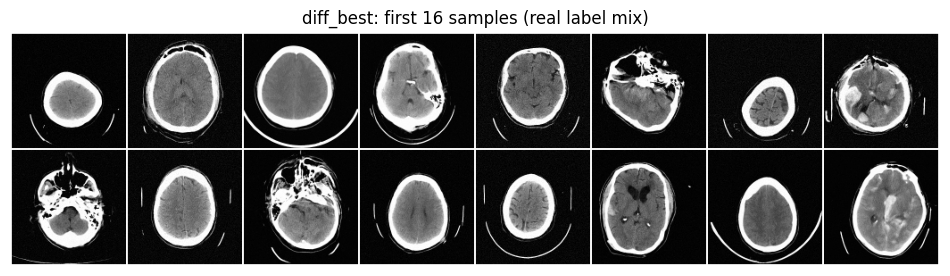

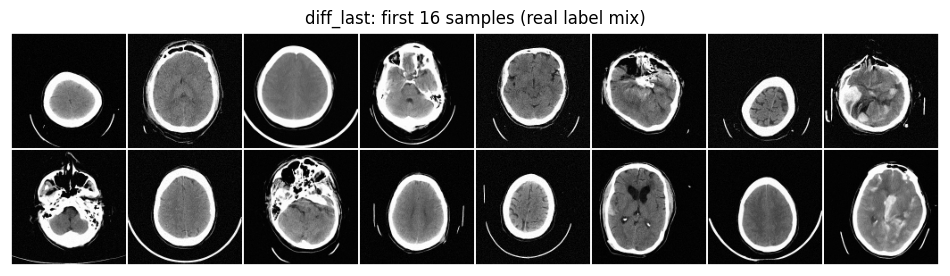

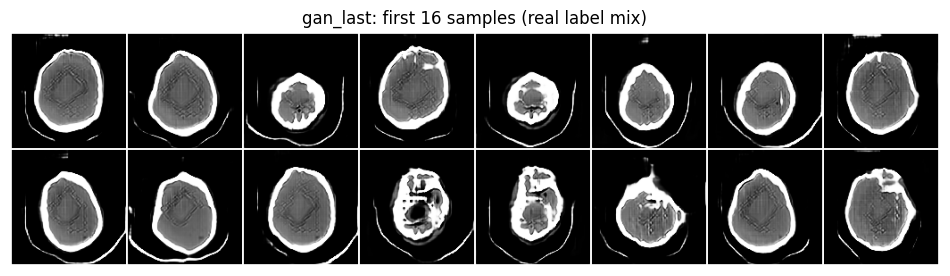

In [ ]:
def make_set(name, kind, which, labels, sc=None, seed=123):
    out = EVAL_DIR / "synth" / name
    if (out / "sampler.json").exists():
        print("exists, skipping:", name); return out
    system = load_model(kind, which)
    generate_synthetic(system, labels, sc or sampler_cfg(kind), lc, out, device=device, seed=seed)
    del system; torch.cuda.empty_cache()
    return out

SET_DIRS = {}
for key, (kind, which) in MODELS.items():
    SET_DIRS[(key, "fid")] = make_set(f"{key}_fid", kind, which, labels_fid)
    SET_DIRS[(key, "healthy")] = make_set(f"{key}_healthy", kind, which, labels_healthy)

def get_u8(key, purpose):
    return load_synth(SET_DIRS[(key, purpose)])[0]

# same labels, one row per model: quick visual sanity check
for key in MODELS:
    show_grid(torch.from_numpy(get_u8(key, "fid")[:16]).float() / 255, nrow=8, title=f"{key}: first 16 samples (real label mix)", figsize=(12, 3.2))

## 2 · FID, KID and diversity
- **Floor:** FID/KID between a random sample of real *training* images and the real reference, at the same N. That is roughly the best any generator can score here.
- **Full set** = real label mix vs the full reference. **Healthy set** = zero-label samples vs real healthy reference slices (the healthy-brain question).
- Lower is better for FID/KID. MS-SSIM between random pairs: **higher = more similar images = less diverse**; real data is the yardstick (a GAN near 1.0 has collapsed).
- Scores are only comparable within one variant and one N. Don't compare full-head FIDs with skull-stripped FIDs directly. Compare each against its own floor.

In [ ]:
def kid_score(real_u8, fake_u8, device, max_n=2000, batch=128, subset=500):
    from torchmetrics.image.kid import KernelInceptionDistance
    n = min(len(real_u8), len(fake_u8), max_n); subset = min(subset, n)
    kid = KernelInceptionDistance(subset_size=subset, normalize=False).to(device)
    for arr, is_real in ((real_u8, True), (fake_u8, False)):
        for i in range(0, n, batch):
            x = torch.from_numpy(np.asarray(arr[i:min(i + batch, n)])).to(device)
            x = x[:, :1].repeat(1, 3, 1, 1) if x.shape[1] == 1 else x[:, :3]
            kid.update(x, real=is_real)
    m, s = kid.compute()
    return float(m), float(s)

def run_eval(set_name, fake_u8, ref_arr, ref_name):
    n = min(len(ref_arr), len(fake_u8))
    f = fid_score(ref_arr, fake_u8, device=device, max_n=n)
    km, ks = kid_score(ref_arr, fake_u8, device, max_n=n)
    log("fid", f, set_name, ref_name, n=n); log("kid", km, set_name, ref_name, n=n, kid_std=ks)
    return f, km

rng = np.random.RandomState(0)
tr_neg_u8 = images[tr[tr["any"] == 0].idx.to_numpy()]
floor_full = train_u8[rng.choice(len(train_u8), N_FID, replace=False)]
floor_neg = tr_neg_u8[rng.choice(len(tr_neg_u8), N_HEALTHY, replace=False)]

run_eval("real_floor_full", floor_full, ref_u8, "real_test")
run_eval("real_floor_healthy", floor_neg, ref_neg_u8, "real_test_healthy")
for key in MODELS:
    run_eval(f"{key}_fid", get_u8(key, "fid"), ref_u8, "real_test")
    run_eval(f"{key}_healthy", get_u8(key, "healthy"), ref_neg_u8, "real_test_healthy")

tab = pd.DataFrame(list(_res.values()))
tab = tab[tab.metric.isin(["fid", "kid"])].pivot_table(index=["set", "ref"], columns="metric", values="value").round(4)
display(tab)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large mem

,metric,fid,kid
set,ref,,
diff_best_fid,real_test,72.6114,0.0305
diff_best_healthy,real_test_healthy,82.3999,0.0327
diff_last_fid,real_test,71.9208,0.0299
diff_last_healthy,real_test_healthy,81.3470,0.0323
gan_last_fid,real_test,155.6399,0.1192
gan_last_healthy,real_test_healthy,162.5480,0.1132
real_floor_full,real_test,11.7408,-0.0000
real_floor_healthy,real_test_healthy,17.9385,-0.0000


In [ ]:
# Diversity: mean MS-SSIM over random pairs (healthy sets, same label). Higher = less diverse.
def ms_ssim_pairs(u8, n_pairs=300, seed=0):
    try:
        from torchmetrics.image import MultiScaleStructuralSimilarityIndexMeasure as MSSSIM
        r = np.random.RandomState(seed)
        a, b = r.randint(0, len(u8), n_pairs), r.randint(0, len(u8), n_pairs)
        keep = a != b; a, b = a[keep], b[keep]
        x = torch.from_numpy(u8[a][:, :1]).float().div(255).to(device)
        y = torch.from_numpy(u8[b][:, :1]).float().div(255).to(device)
        m = MSSSIM(data_range=1.0, betas=(0.0448, 0.2856, 0.3001)).to(device)      # 3 scales: works at 128 px
        return float(m(x, y))
    except Exception as e:
        print("MS-SSIM failed:", repr(e)); return float("nan")

div = {"real_healthy": ms_ssim_pairs(ref_neg_u8)}
for key in MODELS:
    div[f"{key}_healthy"] = ms_ssim_pairs(get_u8(key, "healthy"))
for k, v in div.items():
    log("ms_ssim_pairs", v, k, "self")
display(pd.Series(div, name="mean pairwise MS-SSIM (higher = less diverse)").round(3).to_frame())

,mean pairwise MS-SSIM (higher = less diverse)
real_healthy,0.456
diff_best_healthy,0.429
diff_last_healthy,0.426
gan_last_healthy,0.508


## 3 · Memorization
For every synthetic image: distance to its nearest real **training** image (low-res pixel L2, from `metrics.nearest_real`).
That number alone proves nothing, because similar anatomy gives small distances anyway. The control is the same distance for held-out **real** images.
Synthetic images that sit closer to the training set than held-out real images do are evidence of copying.

control (held-out real -> nearest train): median 3.859, 5th percentile 2.735
diff_best: median NN distance 4.574 | 0.7% of samples closer to train than the 5th percentile of held-out real (about 5% expected if no copying)
diff_last: median NN distance 4.550 | 0.7% of samples closer to train than the 5th percentile of held-out real (about 5% expected if no copying)
gan_last: median NN distance 4.380 | 0.0% of samples closer to train than the 5th percentile of held-out real (about 5% expected if no copying)


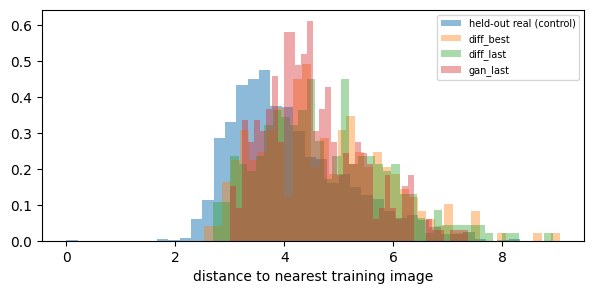

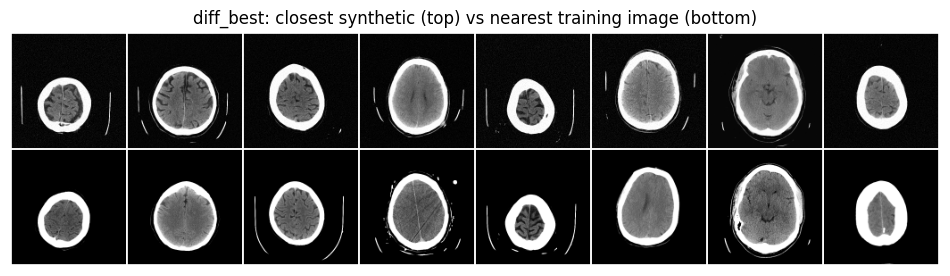

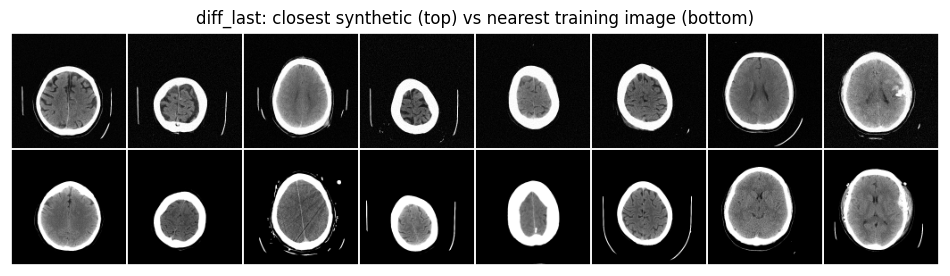

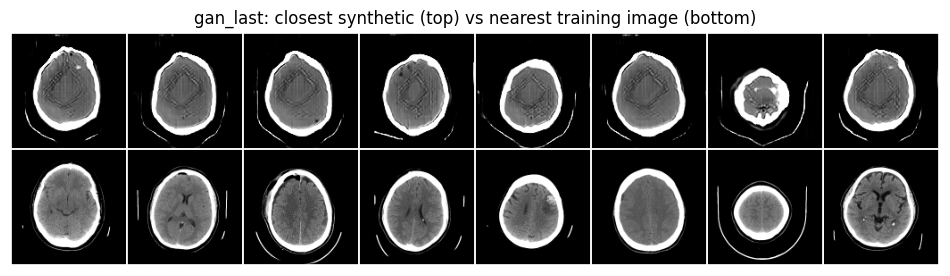

In [ ]:
d_ctrl, _ = nearest_real(ref_u8, train_u8, k=1, device=device, max_real=len(train_u8))
thr = float(np.percentile(d_ctrl, 5))
print(f"control (held-out real -> nearest train): median {np.median(d_ctrl):.3f}, 5th percentile {thr:.3f}")

mem = {}
for key in MODELS:
    fake = get_u8(key, "fid")
    d, idx = nearest_real(fake, train_u8, k=1, device=device, max_real=len(train_u8))
    mem[key] = (d[:, 0], idx[:, 0], fake)
    frac = float((d[:, 0] < thr).mean())
    log("nn_median_dist", np.median(d), f"{key}_fid", "train"); log("frac_closer_than_real_p5", frac, f"{key}_fid", "train")
    print(f"{key}: median NN distance {np.median(d):.3f} | {frac:.1%} of samples closer to train than the 5th percentile of held-out real "
          f"(about 5% expected if no copying)")

plt.figure(figsize=(7, 3))
plt.hist(d_ctrl, bins=40, alpha=.5, density=True, label="held-out real (control)")
for key, (d, _, _) in mem.items():
    plt.hist(d, bins=40, alpha=.4, density=True, label=key)
plt.xlabel("distance to nearest training image"); plt.legend(fontsize=7); plt.show()

for key, (d, idx, fake) in mem.items():       # closest pairs: top row synthetic, bottom row its nearest training image
    o = np.argsort(d)[:8]
    show_grid(torch.cat([torch.from_numpy(fake[o]).float() / 255, torch.from_numpy(train_u8[idx[o]]).float() / 255]),
              nrow=8, title=f"{key}: closest synthetic (top) vs nearest training image (bottom)", figsize=(12, 3.4))

## 4 · Classifier sweep (real + synthetic)
Trained on real train rows plus synthetic images at several ratios, early-stopped on real val, reported on the real **test** split.
The synthetic pool uses the `balance` label plan, which oversamples rare hemorrhage subtypes, so it is not the natural prevalence. That is intended.
Which diffusion checkpoint to use is set by `MAIN_DIFF` in the settings cell. Decide that from the FID/KID table above and rerun from here.

In [ ]:
MAIN = {"diffusion": (MAIN_DIFF, *MODELS[MAIN_DIFF]), "gan": ("gan_last", *MODELS["gan_last"])}
AUG_DIRS = {}
for name, (key, kind, which) in MAIN.items():
    AUG_DIRS[name] = make_set(f"{key}_aug", kind, which, labels_aug)
    s_img, s_man = load_synth(AUG_DIRS[name])
    print(name, "synthetic pool:", s_img.shape, "| hemorrhage fraction:", round(float(s_man["any"].mean()), 3))

exists, skipping: diff_best_aug
diffusion synthetic pool: (498, 1, 128, 128) | hemorrhage fraction: 0.833
exists, skipping: gan_last_aug
gan synthetic pool: (498, 1, 128, 128) | hemorrhage fraction: 0.833


In [ ]:
# time ONE classifier run first (not saved), so you know what the full sweep costs
print("classifier config:", vars(cfg_d.clf) if hasattr(cfg_d.clf, "__dict__") else cfg_d.clf)
t0 = time.time()
r = run_experiment(cfg_d, images, man, None, 0.0, seed=99, tag="timing")
dt = time.time() - t0
runs = len(SEEDS) * (1 + len(RATIOS) * 2)
print(f"one run: {dt / 60:.1f} min, test weighted AUC {r['test_weighted_auc']:.3f} -> sweep of {runs} runs is about {runs * dt / 60:.0f} min")

classifier config: {'arch': 'densenet121', 'epochs': 12, 'lr': 0.0001, 'weight_decay': 0.0001, 'batch_size': 64, 'augmentation': 'classical', 'amp': True, 'seeds': [0, 1, 2]}
one run: 0.5 min, test weighted AUC 0.803 -> sweep of 21 runs is about 11 min


In [ ]:
CLF_CSV = EVAL_DIR / "classifier_sweep.csv"
sweep(cfg_d, images, man, None, {"ratio": [0.0], "seed": SEEDS}, CLF_CSV, device=device, tag="real_only")
for name in MAIN:
    sweep(cfg_d, images, man, load_synth(AUG_DIRS[name]), {"ratio": RATIOS, "seed": SEEDS}, CLF_CSV, device=device, tag=name)
res = pd.read_csv(CLF_CSV)
print(res.groupby(["tag", "synth_ratio"]).size().to_string())

running {'ratio': 0.0, 'seed': 1}
running {'ratio': 0.0, 'seed': 2}
running {'ratio': 0.5, 'seed': 1}
[warn] only 498 synthetic images available (wanted 2774)
running {'ratio': 0.5, 'seed': 2}
[warn] only 498 synthetic images available (wanted 2774)
running {'ratio': 1.0, 'seed': 1}
[warn] only 498 synthetic images available (wanted 5548)
running {'ratio': 1.0, 'seed': 2}
[warn] only 498 synthetic images available (wanted 5548)
running {'ratio': 2.0, 'seed': 0}
[warn] only 498 synthetic images available (wanted 11096)
running {'ratio': 2.0, 'seed': 1}
[warn] only 498 synthetic images available (wanted 11096)
running {'ratio': 2.0, 'seed': 2}
[warn] only 498 synthetic images available (wanted 11096)
running {'ratio': 0.5, 'seed': 1}
[warn] only 498 synthetic images available (wanted 2774)
running {'ratio': 0.5, 'seed': 2}
[warn] only 498 synthetic images available (wanted 2774)
running {'ratio': 1.0, 'seed': 1}
[warn] only 498 synthetic images available (wanted 5548)
running {'ratio': 1

real-only baseline: 0.8120 +/- 0.0183 (n=3 seeds)


,generator,synth_ratio,n_seeds,auc_mean,auc_std,delta_vs_real_only,delta_ci95
0,diffusion,0.5,3,0.8112,0.0108,-0.0008,0.0218
1,diffusion,1.0,3,0.8154,0.0096,0.0034,0.0263
2,diffusion,2.0,3,0.8051,0.0062,-0.0070,0.0316
3,gan,0.5,3,0.8122,0.0086,0.0002,0.0326
4,gan,1.0,3,0.8157,0.0142,0.0037,0.0566
5,gan,2.0,3,0.8114,0.0087,-0.0006,0.0574


An improvement only counts if delta_ci95 is smaller than delta_vs_real_only. With 3 seeds the interval is wide; add seeds before claiming a gain.


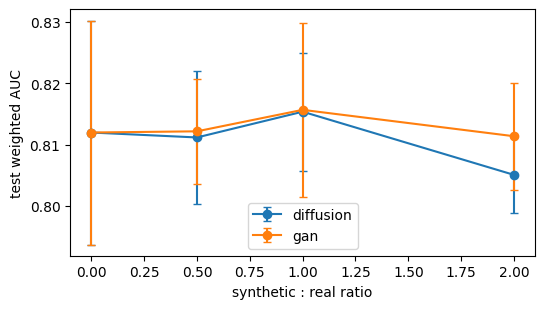

test_auc_epidural  test_auc_intraparenchymal  \
tag       synth_ratio                                                 
diffusion 0.5                      0.594                      0.884   
          1.0                      0.602                      0.890   
          2.0                      0.564                      0.887   
gan       0.5                      0.650                      0.880   
          1.0                      0.658                      0.879   
          2.0                      0.616                      0.880   
real_only 0.0                      0.617                      0.876   

                       test_auc_intraventricular  test_auc_subarachnoid  \
tag       synth_ratio                                                     
diffusion 0.5                              0.926                  0.798   
          1.0                              0.926                  0.801   
          2.0                              0.921                  0.790   
gan       0.5                              0.922                  0.777   
          1.0                              0.919                  0.786   
          2.0                              0.918                  0.791   
real_only 0.0                              0.918                  0.796   

                       test_auc_subdural  test_auc_any  
tag       synth_ratio                                   
diffusion 0.5                      0.802         0.837  
          1.0                      0.803         0.843  
          2.0                      0.803         0.835  
gan       0.5                      0.800         0.828  
          1.0                      0.807         0.831  
          2.0                      0.806         0.834  
real_only 0.0                      0.804         0.837

In [ ]:
def summarize(res, metric="test_weighted_auc"):
    base = res[res.tag == "real_only"].set_index("seed")[metric]
    rows = []
    for (tag, ratio), g in res[res.tag != "real_only"].groupby(["tag", "synth_ratio"]):
        g = g.set_index("seed")
        d = (g[metric] - base.reindex(g.index)).dropna()          # paired by seed: same seed with and without synthetic
        n = len(d)
        ci = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
        rows.append({"generator": tag, "synth_ratio": ratio, "n_seeds": n, "auc_mean": g[metric].mean(),
                     "auc_std": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                     "delta_vs_real_only": d.mean() if n else np.nan, "delta_ci95": ci})
    return pd.DataFrame(rows).round(4)

summ = summarize(res)
b = res[res.tag == "real_only"]
print(f"real-only baseline: {b.test_weighted_auc.mean():.4f} +/- {b.test_weighted_auc.std(ddof=1) if len(b) > 1 else float('nan'):.4f} (n={len(b)} seeds)")
display(summ)
print("An improvement only counts if delta_ci95 is smaller than delta_vs_real_only. With 3 seeds the interval is wide; add seeds before claiming a gain.")

plt.figure(figsize=(6, 3.2))
for name in MAIN:
    s = summ[summ.generator == name]
    x = [0] + list(s.synth_ratio)
    y = [b.test_weighted_auc.mean()] + list(s.auc_mean)
    e = [b.test_weighted_auc.std(ddof=1) if len(b) > 1 else 0] + list(s.auc_std.fillna(0))
    plt.errorbar(x, y, yerr=e, marker="o", capsize=3, label=name)
plt.xlabel("synthetic : real ratio"); plt.ylabel("test weighted AUC"); plt.legend(); plt.show()

auc_cols = [c for c in res.columns if c.startswith("test_auc_")]
display(res.groupby(["tag", "synth_ratio"])[auc_cols].mean().round(3))

## 5 · Ablations (optional)
`RUN_ABLATIONS = True` runs a diffusion guidance-scale sweep at N = `N_ABL`. These FIDs use a different N from the main table, so compare them with each other only.
Checkpoint ablations (diffusion best vs last) are already in the FID/KID table above. Full head vs skull-stripped is a rerun of this notebook with the other variant's runs.

In [ ]:
if RUN_ABLATIONS:
    kind, which = MODELS[MAIN_DIFF]
    labels_abl = LABEL_PLANS.build("match_dist", tr, lc, N_ABL, 5)
    rows = []
    for s in CFG_SCALES:
        sc = cfg_d.override({"sample.cfg_scale": s}).sample
        out = make_set(f"{MAIN_DIFF}_abl_scale{s}", kind, which, labels_abl, sc=sc)
        fake = load_synth(out)[0]
        f, k = run_eval(f"{MAIN_DIFF}_abl_scale{s}", fake, ref_u8[:N_ABL], "real_test_firstN")
        rows.append({"cfg_scale": s, "fid": f, "kid": k})
    display(pd.DataFrame(rows).round(4))
else:
    print("ablations skipped (RUN_ABLATIONS = False)")

sampling:   0%|          | 0/16 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


sampling:   0%|          | 0/16 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


sampling:   0%|          | 0/16 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


,cfg_scale,fid,kid
0,1.0,52.6639,0.0315
1,2.0,52.7724,0.0310
2,4.0,53.9892,0.0303


## 6 · Blinded reader-study export
A shuffled, anonymised panel of real healthy slices and zero-label samples from each generator, with the key kept in a separate file.
Give the reader the images folder and `scoring_sheet.csv` only. **Do not share the key.**

In [ ]:
READER = EVAL_DIR / "reader_study"; (READER / "images").mkdir(parents=True, exist_ok=True)
rng = np.random.RandomState(0)
sources = {"real": ref_neg_u8, "diffusion": get_u8(MAIN_DIFF, "healthy"), "gan": get_u8("gan_last", "healthy")}
items = [(src, arr[i]) for src, arr in sources.items() for i in rng.choice(len(arr), min(N_READER, len(arr)), replace=False)]
rng.shuffle(items)

key_rows = []
for k, (src, img) in enumerate(items):
    iid = f"img_{k:03d}"
    cv2.imwrite(str(READER / "images" / f"{iid}.png"), cv2.resize(img[0], (512, 512), interpolation=cv2.INTER_CUBIC))
    key_rows.append({"id": iid, "source": src})
pd.DataFrame(key_rows).to_csv(READER / "reader_key_DO_NOT_SHARE.csv", index=False)
pd.DataFrame({"id": [r["id"] for r in key_rows], "realism_1to5": "", "looks_real_yes_no": "",
              "abnormality_seen_yes_no": "", "comments": ""}).to_csv(READER / "scoring_sheet.csv", index=False)
print(f"wrote {len(key_rows)} images to {READER / 'images'}")

wrote 90 images to /content/ncl_diffusion_project/eval/full_head/reader_study/images


In [ ]:
final = pd.DataFrame(list(_res.values()))
print("all logged metrics ->", RESULTS)
display(final[["metric", "set", "ref", "value"]].round(4))
print("Next: rerun this notebook with VARIANT='skull_stripped' and the skull-stripped run names, then compare each variant's "
      "numbers against its own real-vs-real floor.")

all logged metrics -> /content/ncl_diffusion_project/eval/full_head/eval_metrics.csv


,metric,set,ref,value
0,fid,real_floor_full,real_test,11.7408
1,kid,real_floor_full,real_test,-0.0000
2,fid,real_floor_healthy,real_test_healthy,17.9385
3,kid,real_floor_healthy,real_test_healthy,-0.0000
4,fid,diff_best_fid,real_test,72.6114
5,kid,diff_best_fid,real_test,0.0305
6,fid,diff_best_healthy,real_test_healthy,82.3999
7,kid,diff_best_healthy,real_test_healthy,0.0327
8,fid,diff_last_fid,real_test,71.9208
9,kid,diff_last_fid,real_test,0.0299


Next: rerun this notebook with VARIANT='skull_stripped' and the skull-stripped run names, then compare each variant's numbers against its own real-vs-real floor.
